**Google Drive mount**

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


**Dataset Extraction**

In [2]:
import zipfile
import os

# Outer ZIP file path
zip_path = '/content/drive/MyDrive/Dataset/Medicinal Plant Leaf Disease Dataset.zip'

# Main extraction folder
extract_path = '/content/medicinal_plant_dataset'
os.makedirs(extract_path, exist_ok=True)

# Step 1: Extract outer ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Outer ZIP extraction completed!")

# Step 2: Locate and extract inner ZIP
inner_zip_path = os.path.join(
    extract_path,
    'Medicinal Plant Leaf Disease Dataset',
    'Medicinal_leaf_dataset.zip'
)

dataset_path = os.path.join(extract_path, 'extracted')
os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(inner_zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_path)

print("Inner ZIP extraction completed!")
print("Dataset extraction completed!")

Outer ZIP extraction completed!
Inner ZIP extraction completed!
Dataset extraction completed!


**Import libraries and set configuration**

In [3]:
import os
import random
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms

from torch.utils.data import DataLoader, Subset
from PIL import Image

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Dataset and image configuration
DATASET_PATH = '/content/medicinal_plant_dataset/extracted/Medicinal_leaf_dataset'

IMG_SIZE = 224
BATCH_SIZE = 32
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Select GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('PyTorch version:', torch.__version__)
print('Torchvision version:', torchvision.__version__)
print('Selected device:', device)

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Selected device: cpu


**Check dataset folder and collect image paths**

In [4]:
if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f'Dataset folder not found: {DATASET_PATH}\n'
        'Check Google Drive mount & dataset path'
    )

class_names = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

image_paths = []
image_labels = []

for class_name in class_names:
    class_path = os.path.join(DATASET_PATH, class_name)

    for file_name in sorted(os.listdir(class_path)):
        if file_name.lower().endswith(IMAGE_EXTENSIONS):
            image_paths.append(os.path.join(class_path, file_name))
            image_labels.append(class_name)

print('Total classes:', len(class_names))
print('Total images:', len(image_paths))
print('\nClass-wise image count:')

class_counts = Counter(image_labels)
for class_name in class_names:
    print(f'{class_name}: {class_counts[class_name]}')

Total classes: 12
Total images: 2547

Class-wise image count:
Kalanchoe_Healthy: 209
Kalanchoe_Web_Blight: 213
Kalanchoe_Yellow: 204
Kalanchoe_Yellow_Blight: 213
Neem_Healthy: 244
Neem_Spot: 211
Neem_Web_Blight: 205
Neem_Yellow: 225
Tulsi_Downy_Mildew: 200
Tulsi_Healthy: 213
Tulsi_Web_Blight: 205
Tulsi_Yellow_Spot: 205


**Visualize sample images (one image per class)**

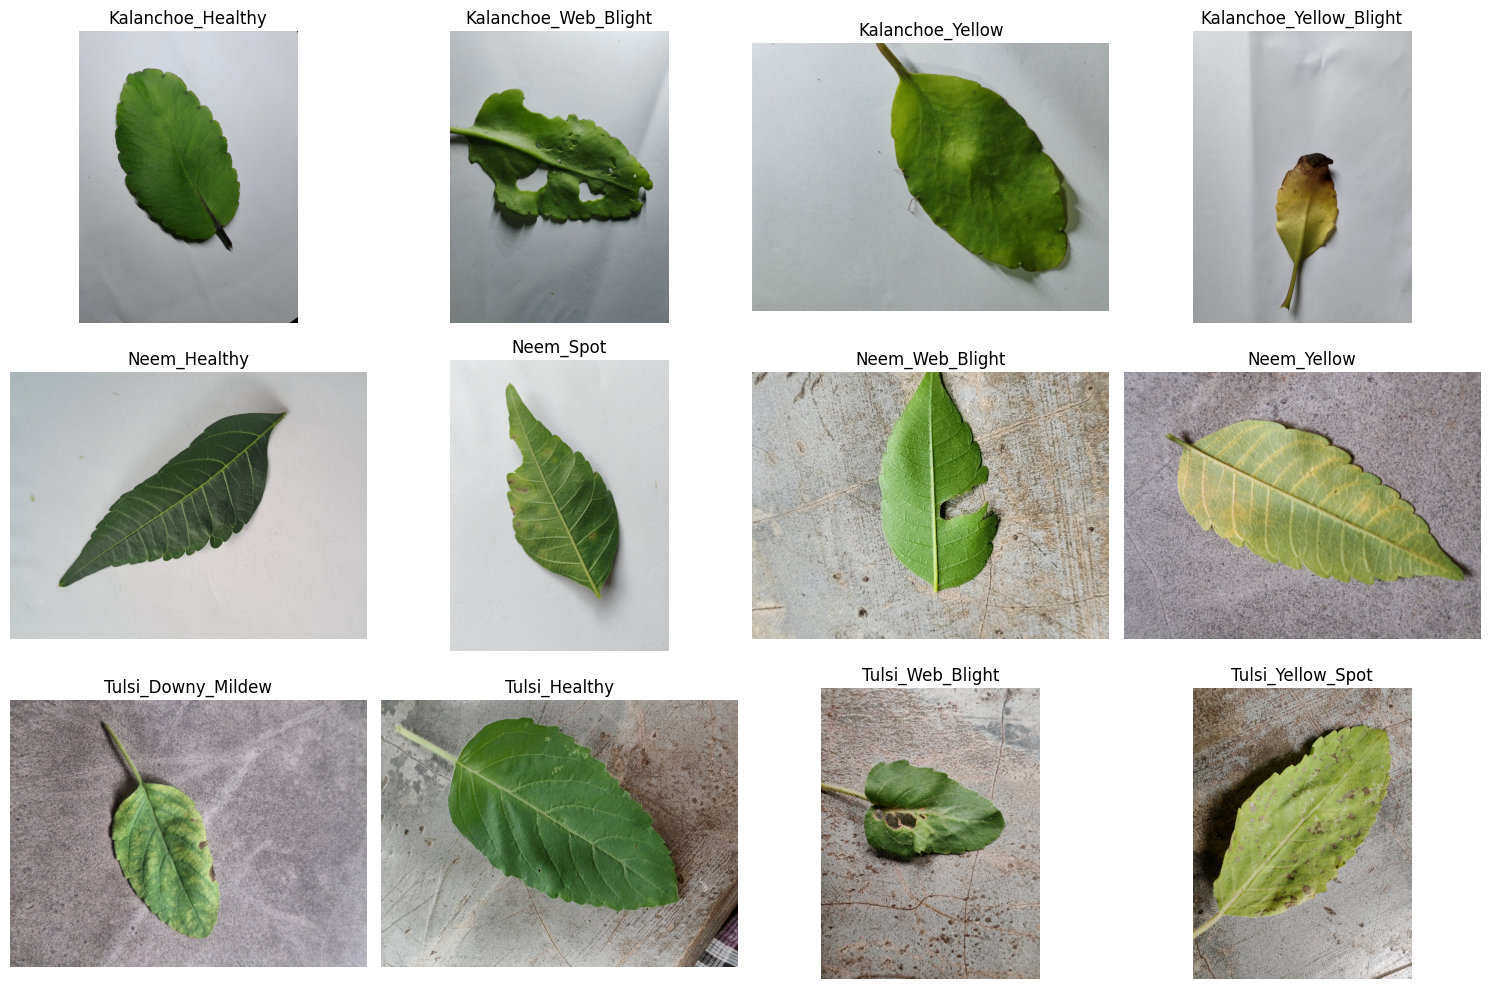

In [5]:
plt.figure(figsize=(15, 10))

for index, class_name in enumerate(class_names):
    class_path = os.path.join(DATASET_PATH, class_name)
    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    if not image_files:
        continue

    image_path = os.path.join(class_path, random.choice(image_files))

    with Image.open(image_path) as img:
        image = img.convert('RGB')

    plt.subplot(3, 4, index + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis('off')

plt.tight_layout()
plt.show()

**Split dataset into Training, Validation and Testing**

In [6]:
# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels
)

# Second split: temporary data into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print('Training images:', len(X_train))
print('Validation images:', len(X_val))
print('Testing images:', len(X_test))
print('Total images:', len(X_train) + len(X_val) + len(X_test))
print('\nNumber of classes:', len(class_names))

Training images: 1782
Validation images: 382
Testing images: 383
Total images: 2547

Number of classes: 12


**Create Datasets using ImageFolder**

In [7]:
# Define image preprocessing
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# Load complete dataset using ImageFolder
full_dataset = datasets.ImageFolder(
    DATASET_PATH,
    transform=basic_transform
)

# Get class names and numeric labels
class_names = full_dataset.classes

print('Total classes:', len(class_names))
print('Class mapping:', full_dataset.class_to_idx)

# Match image paths with ImageFolder indices
path_to_idx = {
    os.path.abspath(path): index
    for index, (path, label) in enumerate(full_dataset.samples)
}

# Use the existing 70:15:15 split
train_indices = [
    path_to_idx[os.path.abspath(path)]
    for path in X_train
]

val_indices = [
    path_to_idx[os.path.abspath(path)]
    for path in X_val
]

test_indices = [
    path_to_idx[os.path.abspath(path)]
    for path in X_test
]

# Create Training, Validation and Testing datasets
train_data = Subset(full_dataset, train_indices)
val_data = Subset(full_dataset, val_indices)
test_data = Subset(full_dataset, test_indices)

print('\nTraining images:', len(train_data))
print('Validation images:', len(val_data))
print('Testing images:', len(test_data))

Total classes: 12
Class mapping: {'Kalanchoe_Healthy': 0, 'Kalanchoe_Web_Blight': 1, 'Kalanchoe_Yellow': 2, 'Kalanchoe_Yellow_Blight': 3, 'Neem_Healthy': 4, 'Neem_Spot': 5, 'Neem_Web_Blight': 6, 'Neem_Yellow': 7, 'Tulsi_Downy_Mildew': 8, 'Tulsi_Healthy': 9, 'Tulsi_Web_Blight': 10, 'Tulsi_Yellow_Spot': 11}

Training images: 1782
Validation images: 382
Testing images: 383


**Create PyTorch DataLoaders**

In [8]:
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print('Train, validation and test DataLoaders are ready.')

Train, validation and test DataLoaders are ready.


**Verify one batch**

In [9]:
images, labels = next(iter(train_loader))

print('Image batch shape:', images.shape)
print('Label batch shape:', labels.shape)
print('Minimum pixel value:', images.min().item())
print('Maximum pixel value:', images.max().item())
print('Number of classes:', len(class_names))
print('Device:', device)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Minimum pixel value: 0.0
Maximum pixel value: 0.9960784316062927
Number of classes: 12
Device: cpu


**Define Reusable Training Function**

In [11]:
# Reusable Training Function

def train_model(model, train_loader, val_loader,
                criterion, optimizer, epochs, device):

    # Store Training History
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_accuracy': [],
        'val_accuracy': []
    }

    # Training Loop
    for epoch in range(epochs):

        # Training Phase
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / total
        epoch_train_accuracy = 100 * correct / total

        # Validation Phase
        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        epoch_val_loss = val_running_loss / val_total
        epoch_val_accuracy = 100 * val_correct / val_total

        # Save History
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)

        history['train_accuracy'].append(epoch_train_accuracy)
        history['val_accuracy'].append(epoch_val_accuracy)

        # Print Results
        print(f"Epoch [{epoch + 1}/{epochs}]")
        print(f"Train Loss: {epoch_train_loss:.4f} | Train Accuracy: {epoch_train_accuracy:.2f}%")
        print(f"Val Loss: {epoch_val_loss:.4f} | Val Accuracy: {epoch_val_accuracy:.2f}%")
        print("-" * 50)

    return history

**Create Reusable Plot Function**

In [12]:
# Reusable Plot Function

def plot_training_history(history, title="Model Performance"):

    plt.figure(figsize=(12, 5))

    # Loss Graph
    plt.subplot(1, 2, 1)

    plt.plot(history['train_loss'], marker='o', label='Training Loss')
    plt.plot(history['val_loss'], marker='o', label='Validation Loss')

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training vs Validation Loss')
    plt.legend()
    plt.grid(True)

    # Accuracy Graph
    plt.subplot(1, 2, 2)

    plt.plot(history['train_accuracy'], marker='o', label='Training Accuracy')
    plt.plot(history['val_accuracy'], marker='o', label='Validation Accuracy')

    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Training vs Validation Accuracy')
    plt.legend()
    plt.grid(True)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

**Create Reusable Experiment Function**

In [23]:
# Reusable Experiment Function

def run_experiment(experiment_name, epochs=10, learning_rate=0.001):

    print("=" * 60)
    print("Experiment:", experiment_name)
    print("Epochs:", epochs)
    print("Learning Rate:", learning_rate)
    print("=" * 60)

    # Create a Fresh Model
    experiment_model = CNNModel().to(device)

    # Define Loss Function
    experiment_criterion = nn.CrossEntropyLoss()

    # Define Optimizer
    experiment_optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=learning_rate
    )

    # Train Model
    experiment_history = train_model(
        model=experiment_model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=experiment_criterion,
        optimizer=experiment_optimizer,
        epochs=epochs,
        device=device
    )

    # Plot Results
    plot_training_history(
        experiment_history,
        title=experiment_name
    )

    return experiment_model, experiment_history

**Build CNN Model**

In [25]:
import torch.nn.functional as F

class CNNModel(nn.Module):

    def __init__(self, num_classes=12):
        super(CNNModel, self).__init__()

        # Convolutional Layers
        self.conv_layers = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU()
        )

        # Fully Connected Layers
        self.fc_layers = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 28 * 28, 256),
            nn.ReLU(),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.conv_layers(x)

        x = self.fc_layers(x)

        return x


# Build CNN Model
model = CNNModel(num_classes=len(class_names)).to(device)

print(model)

# Count trainable parameters
n_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", f"{n_params:,}")

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): ReLU()
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): ReLU()
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=12, bias=True)
  )
)

Total trainable parameters: 25,786,700


**Run Experiments**

Experiment: Experiment 1
Epochs: 5
Learning Rate: 0.001
Epoch [1/5]
Train Loss: 2.3108 | Train Accuracy: 19.08%
Val Loss: 1.7458 | Val Accuracy: 39.01%
--------------------------------------------------
Epoch [2/5]
Train Loss: 1.3105 | Train Accuracy: 52.69%
Val Loss: 1.1424 | Val Accuracy: 57.59%
--------------------------------------------------
Epoch [3/5]
Train Loss: 0.8501 | Train Accuracy: 67.23%
Val Loss: 0.7525 | Val Accuracy: 69.63%
--------------------------------------------------
Epoch [4/5]
Train Loss: 0.5952 | Train Accuracy: 77.38%
Val Loss: 0.5627 | Val Accuracy: 78.01%
--------------------------------------------------
Epoch [5/5]
Train Loss: 0.4697 | Train Accuracy: 80.98%
Val Loss: 0.5426 | Val Accuracy: 79.06%
--------------------------------------------------


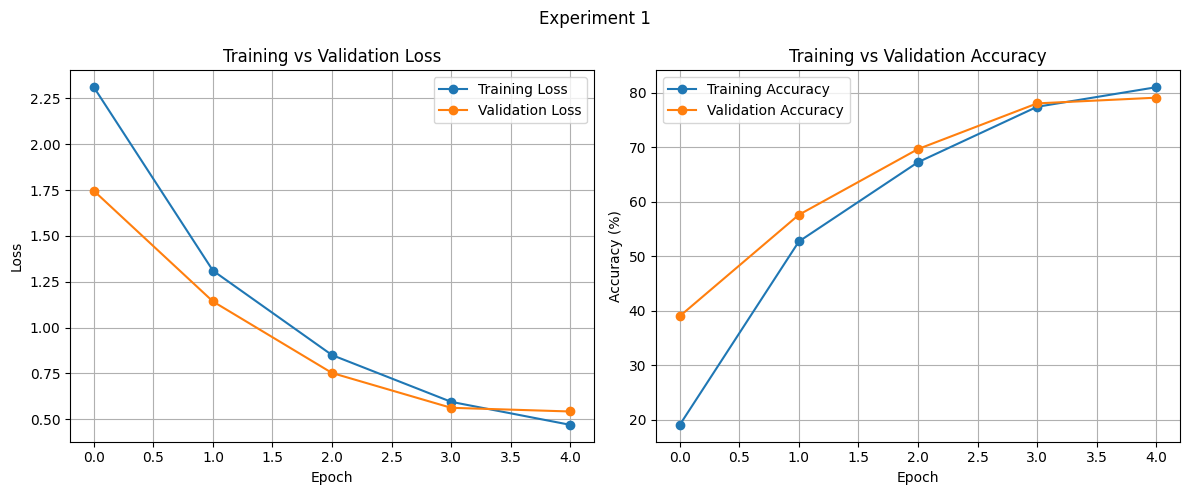

In [14]:
experiment1_model, experiment1_history = run_experiment(
    experiment_name="Experiment 1",
    epochs=5,
    learning_rate=0.001
)

Experiment: Experiment 2
Epochs: 10
Learning Rate: 0.001
Epoch [1/10]
Train Loss: 2.3122 | Train Accuracy: 18.46%
Val Loss: 1.7594 | Val Accuracy: 40.05%
--------------------------------------------------
Epoch [2/10]
Train Loss: 1.3769 | Train Accuracy: 49.16%
Val Loss: 1.0199 | Val Accuracy: 59.69%
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.8762 | Train Accuracy: 67.34%
Val Loss: 0.7575 | Val Accuracy: 70.42%
--------------------------------------------------
Epoch [4/10]
Train Loss: 0.6203 | Train Accuracy: 75.93%
Val Loss: 0.5169 | Val Accuracy: 76.96%
--------------------------------------------------
Epoch [5/10]
Train Loss: 0.5320 | Train Accuracy: 79.07%
Val Loss: 0.6341 | Val Accuracy: 74.87%
--------------------------------------------------
Epoch [6/10]
Train Loss: 0.4869 | Train Accuracy: 82.15%
Val Loss: 0.5976 | Val Accuracy: 75.39%
--------------------------------------------------
Epoch [7/10]
Train Loss: 0.3132 | Train Accuracy: 88.22

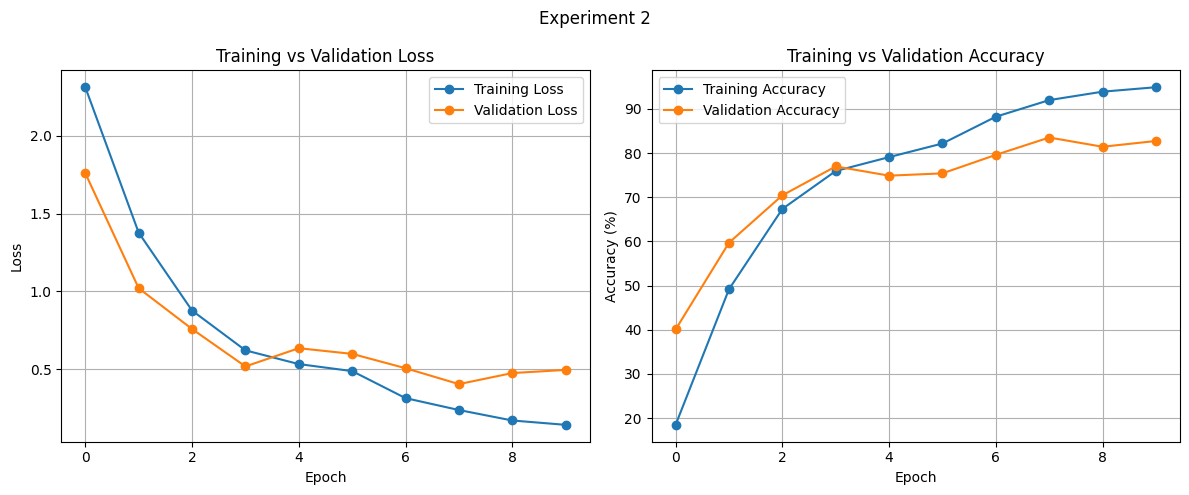

In [14]:
experiment2_model, experiment2_history = run_experiment(
    experiment_name="Experiment 2",
    epochs=10,
    learning_rate=0.001
)

**CNN Model**

In [31]:
import torch.nn.functional as F

class CNNModel(nn.Module):

    def __init__(self, num_classes=12):
        super(CNNModel, self).__init__()

        # Convolutional Layers
        self.conv_layers = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 200, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU()

        )

        # Fully Connected Layers
        self.fc_layers = nn.Sequential(

            nn.Flatten(),

            nn.Linear(200 * 14 * 14, 256),
            nn.ReLU(),
            nn.Linear(256, 350),
            nn.ReLU(),

            nn.Linear(350, num_classes)
        )

    def forward(self, x):

        x = self.conv_layers(x)

        x = self.fc_layers(x)

        return x


# Build CNN Model
model = CNNModel(num_classes=len(class_names)).to(device)

print(model)

# Count trainable parameters
n_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", f"{n_params:,}")

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): ReLU()
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): ReLU()
    (9): Conv2d(128, 200, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): ReLU()
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=39200, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=350, bias=True)
    (4): ReLU()
    (5): Linear(in_feature

Experiment: Experiment 3
Epochs: 10
Learning Rate: 0.0001
Epoch [1/10]
Train Loss: 2.3752 | Train Accuracy: 15.26%
Val Loss: 1.9266 | Val Accuracy: 24.08%
--------------------------------------------------
Epoch [2/10]
Train Loss: 1.6634 | Train Accuracy: 33.05%
Val Loss: 1.3549 | Val Accuracy: 46.60%
--------------------------------------------------
Epoch [3/10]
Train Loss: 1.3326 | Train Accuracy: 47.25%
Val Loss: 1.1922 | Val Accuracy: 46.86%
--------------------------------------------------
Epoch [4/10]
Train Loss: 1.1579 | Train Accuracy: 54.60%
Val Loss: 1.0210 | Val Accuracy: 62.04%
--------------------------------------------------
Epoch [5/10]
Train Loss: 0.9600 | Train Accuracy: 62.51%
Val Loss: 0.8502 | Val Accuracy: 67.80%
--------------------------------------------------
Epoch [6/10]
Train Loss: 0.8687 | Train Accuracy: 66.61%
Val Loss: 0.9030 | Val Accuracy: 66.23%
--------------------------------------------------
Epoch [7/10]
Train Loss: 0.7270 | Train Accuracy: 72.2

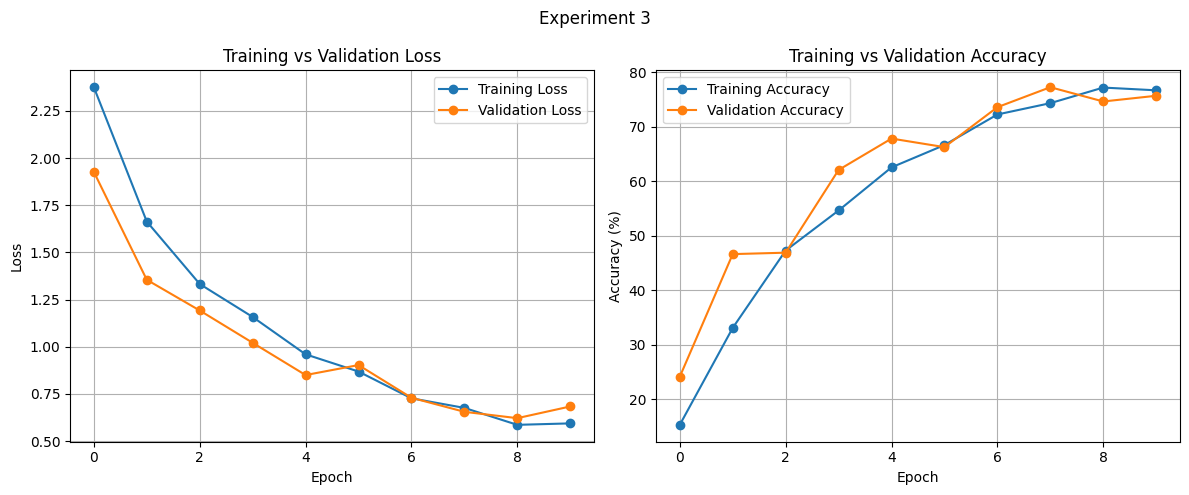

In [32]:
experiment3_model, experiment3_history = run_experiment(
    experiment_name="Experiment 3",
    epochs=10,
    learning_rate=0.0001
)